# Insurance Cost Analysis and Prediction
**Goal:** understand what drives medical insurance charges and predict them.

**What changed from the first version:**
1. The old notebook contained two different versions of the work (the first had a `"femal"` typo and mismatched column names). This is **one clean flow** from top to bottom.
2. Scaling before the train/test split was removed (linear regression does not need it, and it leaks information).
3. Added a feature the data clearly asks for: **smoker x obese interaction**, plus a tree-based model, cross-validation and error metrics.
4. Feature selection (Pearson and chi-square) now uses the correct column names.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from scipy.stats import pearsonr, chi2_contingency
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')

## 1. Load and first look

In [2]:
df = pd.read_csv('insurance.csv')
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 2. Data cleaning

In [5]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
for col in ['sex', 'smoker', 'region']:
    print(col, '->', df[col].unique())

Missing values: 0
Duplicate rows: 1
sex -> <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
smoker -> <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
region -> <ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [6]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows: {rows_before} -> {len(df)}')

Rows: 1338 -> 1337


## 3. Exploratory data analysis

Skewness of charges: 1.52


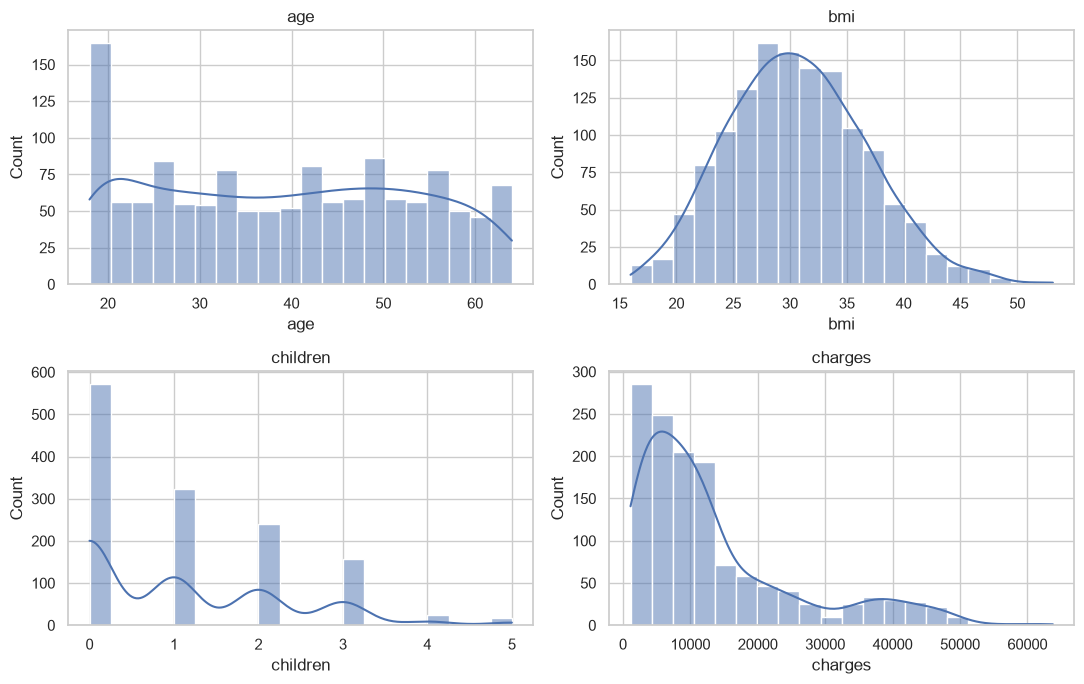

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ['age', 'bmi', 'children', 'charges']):
    sns.histplot(df[col], kde=True, bins=20, ax=ax)
    ax.set_title(col)
plt.tight_layout()
print('Skewness of charges:', round(df['charges'].skew(), 2))

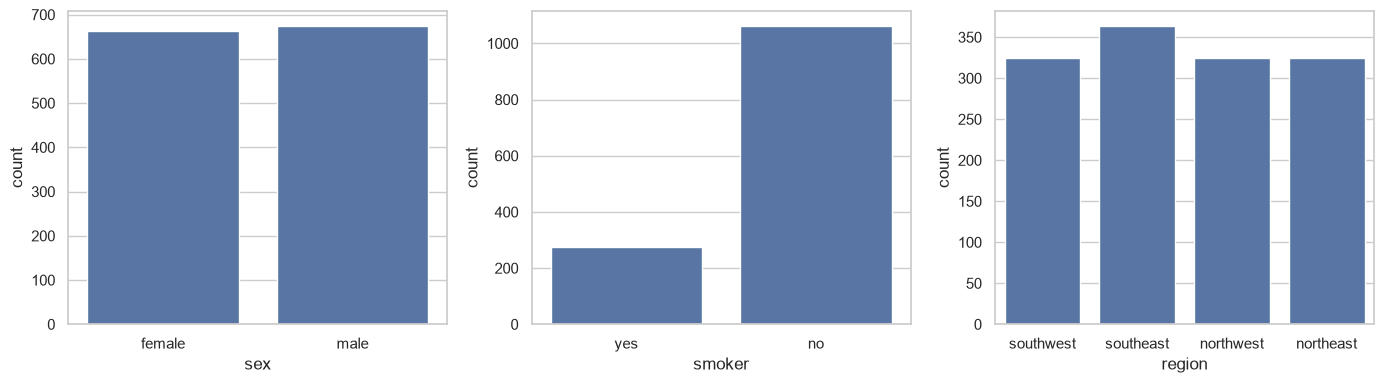

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['sex', 'smoker', 'region']):
    sns.countplot(data=df, x=col, ax=ax)
plt.tight_layout()

           mean   median
smoker                  
no       8441.0   7346.0
yes     32050.0  34456.0


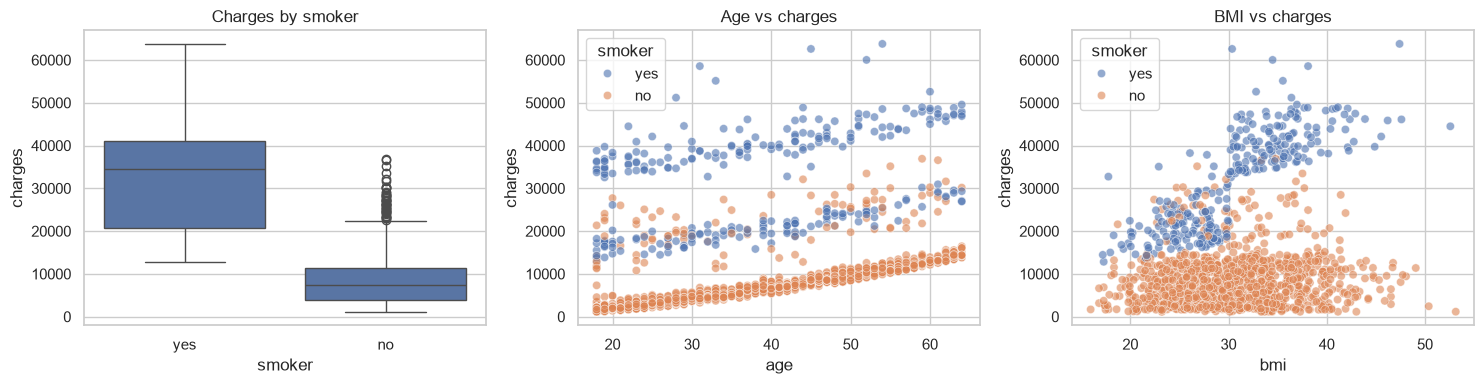

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x='smoker', y='charges', ax=axes[0]); axes[0].set_title('Charges by smoker')
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.6, ax=axes[1]); axes[1].set_title('Age vs charges')
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.6, ax=axes[2]); axes[2].set_title('BMI vs charges')
plt.tight_layout()
print(df.groupby('smoker')['charges'].agg(['mean', 'median']).round(0))

**Observation:** smokers pay far more, and among smokers high BMI pushes charges up even further. That is an interaction a plain linear model cannot see, which we handle below.

## 4. Feature engineering and encoding

In [10]:
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 25, 30, np.inf],
                            labels=['Underweight', 'Normal', 'Overweight', 'Obese'], right=False)
print(df['bmi_category'].value_counts())

df_model = pd.get_dummies(df, columns=['sex', 'smoker', 'region', 'bmi_category'], drop_first=True, dtype=int)
df_model['smoker_obese'] = df_model['smoker_yes'] * df_model['bmi_category_Obese']
df_model.head()

bmi_category
Obese          706
Overweight     386
Normal         225
Underweight     20
Name: count, dtype: int64


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,smoker_obese
0,19,27.900,0,16884.92400,0,1,0,0,1,0,1,0,0
1,18,33.770,1,1725.55230,1,0,0,1,0,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0,1,0,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0,0,1,0,0


## 5. Feature selection: Pearson correlation and chi-square

In [11]:
features = [c for c in df_model.columns if c != 'charges']
pearson = pd.DataFrame({'Feature': features,
                        'Pearson r with charges': [pearsonr(df_model[f], df_model['charges'])[0] for f in features]})
pearson.sort_values('Pearson r with charges', ascending=False).round(3)

,Feature,Pearson r with charges
11,smoker_obese,0.815
4,smoker_yes,0.787
0,age,0.298
10,bmi_category_Obese,0.200
1,bmi,0.198
6,region_southeast,0.074
2,children,0.067
3,sex_male,0.058
5,region_northwest,-0.039
7,region_southwest,-0.044


In [12]:
binary_features = [c for c in features if df_model[c].nunique() == 2]
charge_band = pd.qcut(df_model['charges'], q=4, labels=False)

chi_rows = []
for col in binary_features:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df_model[col], charge_band))
    chi_rows.append({'Feature': col, 'chi2': chi2, 'p_value': p,
                     'Decision (alpha=0.05)': 'Keep' if p < 0.05 else 'Weak evidence'})
pd.DataFrame(chi_rows).sort_values('p_value').round(4)

,Feature,chi2,p_value,Decision (alpha=0.05)
1,smoker_yes,848.2192,0.0000,Keep
8,smoker_obese,488.4022,0.0000,Keep
3,region_southeast,15.9982,0.0011,Keep
0,sex_male,10.2588,0.0165,Keep
7,bmi_category_Obese,8.5157,0.0365,Keep
4,region_southwest,5.0919,0.1652,Weak evidence
6,bmi_category_Overweight,4.2515,0.2356,Weak evidence
5,bmi_category_Normal,3.7395,0.2910,Weak evidence
2,region_northwest,1.1342,0.7688,Weak evidence


## 6. Modelling
Split first, then fit. Linear regression does not need scaling.

In [13]:
X = df_model.drop(columns='charges')
y = df_model['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base_cols = [c for c in X.columns if c != 'smoker_obese']

def report(name, model, cols):
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    r2 = r2_score(y_test, pred)
    n, p = X_test.shape[0], len(cols)
    return {'Model': name, 'R2': r2, 'Adj R2': 1 - (1 - r2) * (n - 1) / (n - p - 1),
            'MAE': mean_absolute_error(y_test, pred), 'RMSE': np.sqrt(mean_squared_error(y_test, pred))}, pred

res1, pred1 = report('Linear Regression (baseline)', LinearRegression(), base_cols)
res2, pred2 = report('Linear Regression + smoker x obese', LinearRegression(), list(X.columns))
res3, pred3 = report('Random Forest', RandomForestRegressor(n_estimators=200, random_state=42), list(X.columns))
res4, pred4 = report('Gradient Boosting', GradientBoostingRegressor(random_state=42), list(X.columns))

results = pd.DataFrame([res1, res2, res3, res4]).round(3)
results

,Model,R2,Adj R2,MAE,RMSE
0,Linear Regression (baseline),0.803,0.794,4334.481,6023.856
1,Linear Regression + smoker x obese,0.905,0.901,2408.058,4177.529
2,Random Forest,0.883,0.878,2622.062,4636.118
3,Gradient Boosting,0.902,0.898,2506.862,4236.382


In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_base = cross_val_score(LinearRegression(), X[base_cols], y, cv=cv, scoring='r2')
cv_inter = cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2')
cv_gb = cross_val_score(GradientBoostingRegressor(random_state=42), X, y, cv=cv, scoring='r2')
print(f'Baseline linear   5-fold R2: {cv_base.mean():.3f}')
print(f'Linear + interaction 5-fold R2: {cv_inter.mean():.3f}')
print(f'Gradient Boosting 5-fold R2: {cv_gb.mean():.3f}')

Baseline linear   5-fold R2: 0.743
Linear + interaction 5-fold R2: 0.858
Gradient Boosting 5-fold R2: 0.855


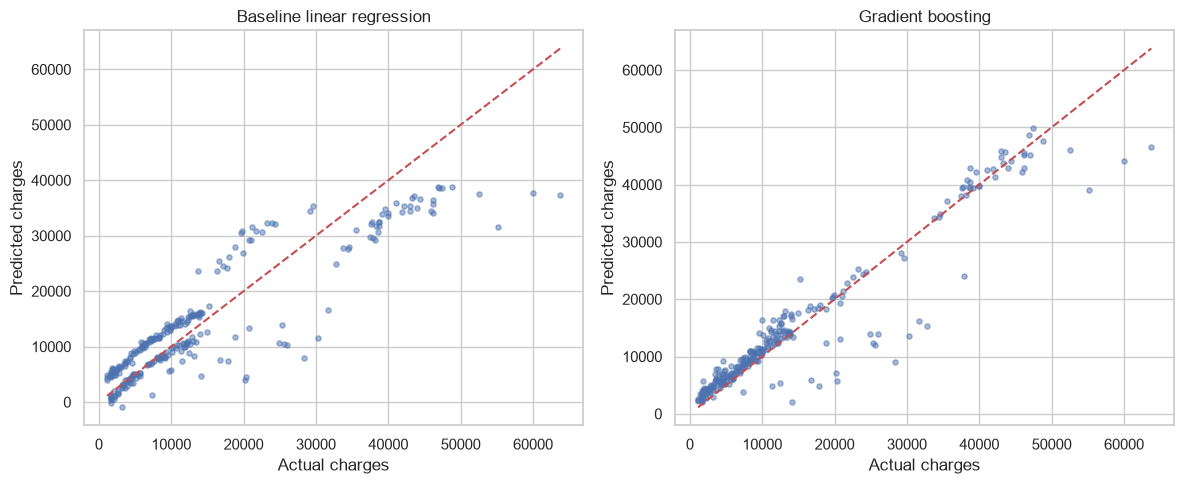

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in zip(axes, [pred1, pred4], ['Baseline linear regression', 'Gradient boosting']):
    ax.scatter(y_test, pred, alpha=0.5, s=14)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--')
    ax.set_xlabel('Actual charges'); ax.set_ylabel('Predicted charges'); ax.set_title(title)
plt.tight_layout()

## 7. Findings (generated from the results above)

In [16]:
from IPython.display import Markdown
means = df.groupby('smoker')['charges'].mean()
Markdown(f'''
- After removing {rows_before - len(df)} duplicate row, the dataset has **{len(df):,}** records.
- Smokers pay about **{means['yes'] / means['no']:.1f}x** more on average (USD {means['yes']:,.0f} vs USD {means['no']:,.0f}).
- A baseline linear regression explains **R2 = {res1['R2']:.2f}** of the variance (average error about USD {res1['MAE']:,.0f}).
- Adding a **smoker x obese interaction** raised R2 to **{res2['R2']:.2f}**, and gradient boosting reached **{res4['R2']:.2f}**.
- 5-fold cross-validation gave baseline R2 = {cv_base.mean():.2f} and interaction model R2 = {cv_inter.mean():.2f}; the single split is a little optimistic, so quote both.
- Smoking status is the strongest driver, followed by age and BMI.
- Limitation: 1,337 records and four regions; the model should not be used for real pricing.
''')


- After removing 1 duplicate row, the dataset has **1,337** records.
- Smokers pay about **3.8x** more on average (USD 32,050 vs USD 8,441).
- A baseline linear regression explains **R2 = 0.80** of the variance (average error about USD 4,334).
- Adding a **smoker x obese interaction** raised R2 to **0.91**, and gradient boosting reached **0.90**.
- 5-fold cross-validation gave baseline R2 = 0.74 and interaction model R2 = 0.86; the single split is a little optimistic, so quote both.
- Smoking status is the strongest driver, followed by age and BMI.
- Limitation: 1,337 records and four regions; the model should not be used for real pricing.
